# Анализ репертуаров CD4 и CD8

Домашняя работа по `UCB_seminar.ipynb`. Анализ повторён для **обеих** популяций: nCD4 и nCD8. Исходные таблицы содержат β-цепь TCR (TRB). BCR из отдельного архива рассматривается отдельно и не смешивается с этими образцами.

Цель: сравнить возрастные группы по длинам CDR3, V/J usage, конвергенции, α-разнообразию и сходству репертуаров. Случайность фиксируется. Выводы описательные, без утверждений о статистической значимости.

## Данные и воспроизводимость

Для пересчёта нужны исходный `ImmuneSem_students.zip` рядом с ноутбуком и пакеты из `requirements.txt`. Можно указать путь к уже распакованным клоносетам в переменной окружения `IMMUNE_DATA_DIR`. Все вычисления и графики приведены в ноутбуке, готовые результаты сохранены в `results/` и `figures/`.

В таблицах нет отдельного столбца UMI. После `by_umi=True` библиотека использует `cloneCount`. В этом наборе данные предварительно обработаны MiGEC, а суммы функциональных `cloneCount` совпадают с `UMI_functional` из метаданных. Поэтому далее это **молекулярные наблюдения**, а не сырые FASTQ-риды и не число клеток.

Использована библиотека семинара `repseq` 0.1.3. Исправлен только путь к встроенной таблице аминокислотных свойств, которая в установленной библиотеке по умолчанию ищется в домашней папке автора.

In [1]:
from pathlib import Path
import contextlib
import hashlib
import importlib.metadata
import importlib.resources
import io as stringio
import json
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import sparse
from scipy.special import gammaln
from scipy.stats import spearmanr
from repseq import io as rsio, stats, clone_filter as clf, beta

GROUPS = ['preterm', 'term', 'late', 'children', 'adults', 'older_adults']
PALETTE = dict(zip(GROUPS, sns.color_palette('colorblind', 6)))
DEPTHS = {'nCD4': 5000, 'nCD8': 6000}
SEEDS = [100, 101, 102]
sns.set_theme(style='whitegrid', font_scale=1.0)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 150,
                     'font.family': 'DejaVu Sans'})
stats.AA_PROPS_PATH = str(importlib.resources.files('repseq') / 'resourses' / 'aa_property_table.txt')


def find_input():
    import os
    candidates = [Path(os.environ.get('IMMUNE_DATA_DIR', 'data/ucb_figshare')),
                  Path('ImmuneSem/data/ucb_figshare'),
                  Path('../../work/ImmuneSem/data/ucb_figshare'),
                  Path('../work/ImmuneSem/data/ucb_figshare')]
    for p in candidates:
        if (p / 'ucb_figshare_TRB_metadata.csv').is_file():
            return p.resolve()
    archives = [Path('ImmuneSem_students.zip'), Path('../ImmuneSem_students.zip'),
                Path('/home/euegene/Downloads/Telegram Desktop/ImmuneSem_students.zip')]
    for archive in archives:
        if archive.is_file():
            with zipfile.ZipFile(archive) as z:
                for member in z.namelist():
                    if member.startswith('ImmuneSem/data/ucb_figshare/'):
                        z.extract(member, 'work/input')
            return Path('work/input/ImmuneSem/data/ucb_figshare').resolve()
    raise FileNotFoundError('Укажите IMMUNE_DATA_DIR или положите ImmuneSem_students.zip рядом с ноутбуком.')


def load_metadata(data_dir):
    m = pd.read_csv(data_dir / 'ucb_figshare_TRB_metadata.csv')
    m['experimental_group'] = pd.Categorical(m.experimental_group, categories=GROUPS, ordered=True)
    assert m.sample_id.is_unique
    assert not m[['sample_id', 'subset', 'experimental_group']].isna().any().any()
    assert all((data_dir / f).is_file() for f in m.filename)
    return m


def downsample(clonoset, depth, seed, sample_id):
    counts = clonoset['count'].to_numpy(dtype=np.int64)
    assert np.all(counts >= 0) and counts.sum() >= depth
    stable_id = int.from_bytes(hashlib.sha256(sample_id.encode()).digest()[:4], 'little')
    rng = np.random.default_rng(np.random.SeedSequence([seed, stable_id]))
    sampled = rng.multivariate_hypergeometric(counts, depth)
    d = clonoset.loc[sampled > 0].copy()
    d['count'] = sampled[sampled > 0]
    d['freq'] = d['count'] / depth
    assert d['count'].sum() == depth
    return d.reset_index(drop=True)


def exact_rarefaction(counts, depth):
    counts = np.asarray(counts, dtype=np.int64)
    values, multiplicity = np.unique(counts, return_counts=True)
    total = int(counts.sum())
    if depth == total:
        return float(len(counts))
    log_total = gammaln(total + 1) - gammaln(depth + 1) - gammaln(total - depth + 1)
    available = total - values
    p_missed = np.zeros(len(values))
    ok = available >= depth
    log_missed = (gammaln(available[ok] + 1) - gammaln(depth + 1)
                  - gammaln(available[ok] - depth + 1) - log_total)
    p_missed[ok] = np.exp(np.minimum(log_missed, 0))
    return float(np.sum(multiplicity * (1 - p_missed)))


def compute_subset(subset, metadata, data_dir, output):
    out = output / subset
    (out / 'normalized').mkdir(parents=True, exist_ok=True)
    samples = metadata.loc[metadata.subset.eq(subset)].sort_values('sample_id')
    depth = DEPTHS[subset]
    qc_rows, properties, lengths, usage_rows = [], [], [], []
    diversity_rows, convergence_rows, rarefaction_rows = [], [], []
    normalized, manifests = {}, []
    functional_filter = clf.Filter(functionality='f', by_umi=True, seed=100)
    for row in samples.itertuples():
        filename = data_dir / row.filename
        raw = rsio.read_clonoset(filename)
        q = stats.calculate_clonoset_stats_cl(raw)
        assert q['reads_func'] == row.UMI_functional, row.sample_id
        assert q['clones_func'] == row.clonotypes_functional, row.sample_id
        qc_rows.append({'sample_id': row.sample_id, **q})
        with contextlib.redirect_stdout(stringio.StringIO()):
            functional = functional_filter.apply(raw)
        assert int(functional['count'].sum()) >= depth
        p = stats.calculate_cdr3_properties_cl(functional)
        properties.append({'sample_id': row.sample_id, 'mean_cdr3aa_len': p['mean_cdr3nt_len'] / 3, **p})
        weighted_lengths = functional.assign(cdr3_length=functional.cdr3aa.str.len()).groupby('cdr3_length')['freq'].sum()
        lengths += [{'sample_id': row.sample_id, 'cdr3_length': int(k), 'freq': v} for k, v in weighted_lengths.items()]
        for segment in ['v', 'j']:
            usage = functional.groupby(segment)['freq'].sum()
            usage_rows += [{'sample_id': row.sample_id, 'segment': segment, 'gene': k, 'usage': v} for k, v in usage.items()]
        for current_depth in [depth, depth // 2]:
            for seed in SEEDS:
                d = downsample(functional, current_depth, seed, row.sample_id)
                div = stats.calculate_diversity_stats_cl(d)
                div['top10_fraction'] = d['count'].nlargest(10).sum() / current_depth
                diversity_rows.append({'sample_id': row.sample_id, 'depth': current_depth, 'seed': seed, **div})
                convergence_rows.append({'sample_id': row.sample_id, 'depth': current_depth, 'seed': seed,
                                         **stats.calculate_convergence_cl(d)})
                if current_depth == depth and seed == SEEDS[0]:
                    normalized[row.sample_id] = d
                    d.to_csv(out / 'normalized' / (row.sample_id + '.tsv'), sep='\t', index=False)
        total = int(functional['count'].sum())
        depths = np.unique(np.r_[np.geomspace(100, total, 20).astype(int), depth // 2, depth, total])
        rarefaction_rows += [{'sample_id': row.sample_id, 'rarefaction_depth': int(n),
                             'diversity': exact_rarefaction(functional['count'], int(n))} for n in depths]
        manifests.append({'sample_id': row.sample_id, 'filename': row.filename,
                          'sha256': hashlib.file_digest(open(filename, 'rb'), 'sha256').hexdigest()})
        print(f'{subset}: {row.sample_id}, functional={total}, clones={len(functional)}', flush=True)

    result = {'qc': pd.DataFrame(qc_rows), 'properties': pd.DataFrame(properties),
              'lengths': pd.DataFrame(lengths), 'usage': pd.DataFrame(usage_rows),
              'diversity_repeats': pd.DataFrame(diversity_rows),
              'convergence_repeats': pd.DataFrame(convergence_rows),
              'rarefaction': pd.DataFrame(rarefaction_rows), 'manifest': pd.DataFrame(manifests)}
    for metric in ['diversity', 'convergence']:
        result[metric] = result[metric + '_repeats'].groupby(['sample_id', 'depth'], as_index=False).mean(numeric_only=True).drop(columns='seed')

    all_keys, matrices, ids = {}, [], list(normalized)
    for sample_id in ids:
        d = normalized[sample_id]
        pooled = d.groupby(['cdr3aa', 'v'], dropna=False)['freq'].sum()
        columns, values = [], []
        for key, frequency in pooled.items():
            if key not in all_keys:
                all_keys[key] = len(all_keys)
            columns.append(all_keys[key])
            values.append(np.sqrt(frequency))
        matrices.append((columns, values))
    rr, cc, vv = [], [], []
    for i, (columns, values) in enumerate(matrices):
        rr.extend([i] * len(columns)); cc.extend(columns); vv.extend(values)
    x = sparse.csr_matrix((vv, (rr, cc)), shape=(len(ids), len(all_keys)))
    f2 = (x @ x.T).toarray()
    assert np.allclose(f2, f2.T) and np.allclose(np.diag(f2), 1)
    assert f2.min() >= -1e-12 and f2.max() <= 1 + 1e-12
    result['f2'] = pd.DataFrame(np.clip(f2, 0, 1), index=ids, columns=ids)
    result['f2'].index.name = 'sample_id'
    result['mds'] = beta.mds(result['f2'])
    distances = -np.log10(np.maximum(f2, np.min(f2[f2 > 0]) / 10))
    np.fill_diagonal(distances, 0)
    centering = np.eye(len(ids)) - np.ones((len(ids), len(ids))) / len(ids)
    eigenvalues = np.linalg.eigvalsh(-0.5 * centering @ (distances ** 2) @ centering)[::-1]
    positive = eigenvalues[eigenvalues > 0]
    result['mds_quality'] = pd.DataFrame([{'positive_variance_2d': positive[:2].sum() / positive.sum(),
                                         'negative_inertia_fraction': -eigenvalues[eigenvalues < 0].sum() / np.abs(eigenvalues).sum()}])
    for name, frame in result.items():
        frame.to_csv(out / (name + '.csv'), index=(name == 'f2'))
    return result


def save_figure(fig, output, name):
    output.mkdir(parents=True, exist_ok=True)
    fig.savefig(output / (name + '.png'), bbox_inches='tight')
    plt.show()
    plt.close(fig)


def group_dots(ax, table, column, ylabel):
    order = [g for g in GROUPS if g in table.experimental_group.values]
    sns.boxplot(data=table, x='experimental_group', y=column, order=order,
                color='#dce4eb', showfliers=False, width=.6, ax=ax)
    # Fixed offsets preserve the same positions on every rerun.
    offsets = np.random.default_rng(0).uniform(-.13, .13, len(table))
    for g_index, g in enumerate(order):
        mask = table.experimental_group.eq(g).to_numpy()
        ax.scatter(g_index + offsets[mask], table.loc[mask, column], c=[PALETTE[g]], s=33, zorder=3)
    ax.set_xlabel('Группа'); ax.set_ylabel(ylabel)
    ax.tick_params(axis='x', rotation=30)


def plot_qc(subset, r, metadata, figures):
    t = r['qc'].merge(metadata[['sample_id', 'experimental_group']])
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    group_dots(axes[0], t, 'reads_func', 'Функциональные наблюдения')
    group_dots(axes[1], t, 'clones_func', 'Функциональные клонотипы')
    axes[0].axhline(DEPTHS[subset], ls='--', c='black', lw=1, label=f'downsample={DEPTHS[subset]}')
    axes[0].set_yscale('log'); axes[1].set_yscale('log'); axes[0].legend()
    fig.suptitle(subset + ': исходная глубина и богатство'); fig.tight_layout()
    save_figure(fig, figures, subset + '_qc')


def plot_properties(subset, r, metadata, figures):
    t = r['properties'].merge(metadata[['sample_id', 'experimental_group']])
    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    fields = [('mean_cdr3aa_len', 'Средняя CDR3, аминокислоты'),
              ('mean_insert_size', 'Средняя длина вставок, нт'),
              ('zero_insert_freq', 'Доля CDR3 без вставок'),
              ('cdr3_5_charge', 'Заряд центральных 5 остатков'),
              ('cdr3_5_hydropathy', 'Гидропатия центральных 5 остатков'),
              ('cdr3_full_charge', 'Суммарный заряд CDR3')]
    for ax, (field, label) in zip(axes.flat, fields):
        group_dots(ax, t, field, label)
    fig.suptitle(subset + ': свойства продуктивных CDR3'); fig.tight_layout()
    save_figure(fig, figures, subset + '_properties')


def plot_lengths(subset, r, metadata, figures):
    t = r['lengths'].merge(metadata[['sample_id', 'experimental_group']])
    all_lengths = np.arange(t.cdr3_length.min(), t.cdr3_length.max() + 1)
    wide = t.pivot_table(index='sample_id', columns='cdr3_length', values='freq', fill_value=0).reindex(columns=all_lengths, fill_value=0)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for ax, selected in [(axes[0], GROUPS), (axes[1], ['preterm', 'late'])]:
        for g in selected:
            ids = metadata.loc[(metadata.subset == subset) & (metadata.experimental_group == g), 'sample_id']
            d = wide.loc[ids].astype(float)
            avg = d.mean(axis=0)
            ax.plot(all_lengths, avg, color=PALETTE[g], label=f'{g}, n={len(ids)}')
            ax.fill_between(all_lengths, d.min(axis=0), d.max(axis=0), color=PALETTE[g], alpha=.07)
        ax.set_xlim(5, 27); ax.set_xlabel('Длина CDR3, аминокислоты'); ax.set_ylabel('Доля наблюдений'); ax.legend(fontsize=8)
    axes[0].set_title('Средние профили групп'); axes[1].set_title('Preterm и late, диапазон между образцами')
    fig.suptitle(subset + ': длины CDR3'); fig.tight_layout()
    save_figure(fig, figures, subset + '_lengths')


def plot_usage(subset, r, metadata, figures):
    usage = r['usage'].merge(metadata[['sample_id', 'experimental_group']])
    fig, axes = plt.subplots(1, 2, figsize=(14, 7), gridspec_kw={'width_ratios': [1.6, 1]})
    for segment, ax, title in [('v', axes[0], 'V: 25 наиболее частых генов'), ('j', axes[1], 'J: все гены')]:
        t = usage.loc[usage.segment.eq(segment)]
        wide = t.pivot(index='sample_id', columns='gene', values='usage').fillna(0)
        top = wide.mean().nlargest(25 if segment == 'v' else 30).index
        wide = wide[top].merge(metadata[['sample_id', 'experimental_group']], on='sample_id')
        group_mean = wide.groupby('experimental_group', observed=True)[top].mean().reindex(GROUPS)
        sns.heatmap(group_mean.T, cmap='YlGnBu', ax=ax, cbar_kws={'label': 'Средняя доля наблюдений'})
        ax.set_title(title); ax.set_xlabel('Группа'); ax.set_ylabel('Ген')
    fig.suptitle(subset + ': V/J usage, равный вес каждого образца'); fig.tight_layout()
    save_figure(fig, figures, subset + '_usage')


def plot_alpha(subset, r, metadata, figures):
    t = r['diversity'].loc[r['diversity'].depth.eq(DEPTHS[subset])].merge(metadata[['sample_id', 'experimental_group']])
    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    fields = [('diversity', 'Богатство, число клонотипов'), ('shannon_wiener', 'Shannon, натуральный логарифм'),
              ('clonality', 'Клональность 1 - H / ln(S)'), ('inverse_simpson', 'Inverse Simpson'),
              ('goods_coverage', "Good's coverage"), ('top10_fraction', 'Доля 10 крупнейших клонотипов')]
    for ax, (field, label) in zip(axes.flat, fields):
        group_dots(ax, t, field, label)
    fig.suptitle(f'{subset}: разнообразие, глубина {DEPTHS[subset]}, среднее 3 субсэмплов'); fig.tight_layout()
    save_figure(fig, figures, subset + '_alpha')


def plot_convergence(subset, r, metadata, figures):
    t = r['convergence'].loc[r['convergence'].depth.eq(DEPTHS[subset])].merge(metadata[['sample_id', 'experimental_group']])
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for ax, field in zip(axes, ['convergence', 'convergence_v', 'convergence_vj']):
        group_dots(ax, t, field, field)
    fig.suptitle(subset + ': конвергенция, среднее 3 субсэмплов'); fig.tight_layout()
    save_figure(fig, figures, subset + '_convergence')


def plot_rarefaction(subset, r, metadata, figures):
    t = r['rarefaction'].merge(metadata[['sample_id', 'experimental_group']])
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for sample_id, d in t.groupby('sample_id'):
        g = d.experimental_group.iloc[0]
        for ax in axes:
            ax.plot(d.rarefaction_depth, d.diversity, color=PALETTE[g], alpha=.6, lw=1)
    for ax in axes:
        ax.axvline(DEPTHS[subset], ls='--', c='black', lw=1)
        ax.set_xlabel('Глубина, молекулярные наблюдения'); ax.set_ylabel('Ожидаемое число клонотипов')
    axes[1].set_xscale('log')
    handles = [plt.Line2D([], [], color=PALETTE[g], label=g) for g in GROUPS]
    axes[1].legend(handles=handles, fontsize=8)
    axes[0].set_title('Линейная шкала'); axes[1].set_title('Логарифмическая шкала')
    fig.suptitle(subset + ': точная гипергеометрическая rarefaction'); fig.tight_layout()
    save_figure(fig, figures, subset + '_rarefaction')


def plot_beta(subset, r, metadata, figures):
    m = metadata.loc[metadata.subset.eq(subset)].sort_values(['experimental_group', 'sample_id'])
    ids = m.sample_id.tolist()
    fig, axes = plt.subplots(1, 2, figsize=(15, 7), gridspec_kw={'width_ratios': [1.3, 1]})
    mask = np.eye(len(ids), dtype=bool)
    sns.heatmap(r['f2'].loc[ids, ids], mask=mask, cmap='magma', ax=axes[0],
                cbar_kws={'label': 'F2 (CDR3aa + V)'}, xticklabels=True, yticklabels=True)
    axes[0].tick_params(labelsize=6)
    axes[0].set_title('F2, диагональ скрыта')
    t = r['mds'].merge(metadata[['sample_id', 'experimental_group']])
    for g in GROUPS:
        d = t.loc[t.experimental_group.eq(g)]
        axes[1].scatter(d.MDS1, d.MDS2, color=PALETTE[g], s=50, label=f'{g}, n={len(d)}')
        axes[1].scatter(d.MDS1.mean(), d.MDS2.mean(), marker='x', s=90, lw=2, color=PALETTE[g])
    axes[1].set(xlabel='MDS1 (условная координата)', ylabel='MDS2 (условная координата)', title='Классический MDS: d = -log10(F2)')
    axes[1].legend(fontsize=8)
    fig.suptitle(f'{subset}: сходство после даунсэмпла {DEPTHS[subset]}, seed=100'); fig.tight_layout()
    save_figure(fig, figures, subset + '_beta')


def plot_sensitivity(subset, r, metadata, figures):
    t = r['diversity'].merge(metadata[['sample_id', 'experimental_group']])
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
    for ax, (field, label) in zip(axes, [('diversity', 'Богатство'), ('shannon_wiener', 'Shannon'), ('clonality', 'Клональность')]):
        for sample_id, d in t.groupby('sample_id'):
            d = d.sort_values('depth'); g = d.experimental_group.iloc[0]
            ax.plot(d.depth, d[field], color=PALETTE[g], marker='o', ms=3, lw=1, alpha=.65)
        ax.set_xticks([DEPTHS[subset] // 2, DEPTHS[subset]])
        ax.set_xlabel('Глубина субсэмпла'); ax.set_ylabel(label)
    handles = [plt.Line2D([], [], color=PALETTE[g], label=g) for g in GROUPS]
    axes[2].legend(handles=handles, fontsize=8)
    fig.suptitle(subset + ': чувствительность к глубине, линии соединяют один образец'); fig.tight_layout()
    save_figure(fig, figures, subset + '_sensitivity')


def summarize(subset, r, metadata):
    depth = DEPTHS[subset]
    ids = ['sample_id', 'experimental_group']
    t = r['qc'].merge(r['properties'][['sample_id', 'mean_cdr3aa_len', 'mean_insert_size', 'zero_insert_freq']])
    t = t.merge(r['diversity'].loc[r['diversity'].depth.eq(depth)]).merge(r['convergence'].loc[r['convergence'].depth.eq(depth)], on=['sample_id', 'depth'])
    t = t.merge(metadata[ids])
    columns = ['reads_func', 'clones_func', 'mean_cdr3aa_len', 'mean_insert_size', 'zero_insert_freq',
               'diversity', 'shannon_wiener', 'clonality', 'inverse_simpson', 'convergence', 'convergence_vj', 'top10_fraction']
    summary = t.groupby('experimental_group', observed=True)[columns].median().reindex(GROUPS)
    summary.insert(0, 'n', t.groupby('experimental_group', observed=True).size())
    wide = r['diversity'].pivot(index='sample_id', columns='depth', values='diversity')
    stability = {'richness_rank_spearman': spearmanr(wide[depth], wide[depth // 2]).statistic,
                 'median_richness_change_percent': np.median((wide[depth // 2] / wide[depth] - 1) * 100)}
    pairs = []
    indexed = metadata.set_index('sample_id')
    for i, a in enumerate(r['f2'].index):
        for b in r['f2'].index[i + 1:]:
            pairs.append({'sample1': a, 'sample2': b, 'group1': indexed.loc[a, 'experimental_group'],
                          'group2': indexed.loc[b, 'experimental_group'], 'f2': r['f2'].loc[a, b]})
    pairs = pd.DataFrame(pairs)
    return summary, pd.DataFrame([stability]), pairs

In [2]:
DATA_DIR = find_input()
OUTPUT = Path('results')
FIGURES = Path('figures')
OUTPUT.mkdir(exist_ok=True)
metadata = load_metadata(DATA_DIR)
metadata.to_csv(OUTPUT / 'metadata.csv', index=False)
versions = {p: importlib.metadata.version(p) for p in ['repseq', 'numpy', 'pandas', 'scipy', 'matplotlib', 'seaborn']}
print('Версии:', versions)
(OUTPUT / 'versions.json').write_text(json.dumps(versions, indent=2))
group_counts = metadata.groupby(['subset', 'experimental_group'], observed=True).size().unstack(fill_value=0).reindex(columns=GROUPS)
display(group_counts)
display(metadata.groupby('subset')[['UMI_functional', 'clonotypes_functional']].agg(['min', 'median', 'max']))

Версии: {'repseq': '0.1.3', 'numpy': '1.26.4', 'pandas': '2.2.3', 'scipy': '1.11.4', 'matplotlib': '3.11.2', 'seaborn': '0.13.2'}


experimental_group,preterm,term,late,children,adults,older_adults
subset,,,,,,
nCD4,3,6,4,4,9,4
nCD8,3,6,4,4,4,6
nTreg,3,6,4,4,9,4


UMI_functional                  clonotypes_functional                 
                  min   median     max                   min   median     max
subset                                                                       
nCD4             5912  48871.0  254528                  4508  35065.0  119344
nCD8             6368  50019.0  193529                  4931  34463.0  103879
nTreg            4644  17698.0  125797                  3201  10490.0   57720

В CD4: 30 образцов, в CD8: 27. В порядке preterm, term, late, children, adults, older_adults получено CD4: **3, 6, 4, 4, 9, 4**, CD8: **3, 6, 4, 4, 4, 6**. Один образец соответствует одному донору внутри популяции, повторы даунсэмплирования не увеличивают число биологических реплик.

**Ограничения метаданных.** В preterm и late CD4 имеют гейт `CD3+CD4+`, в PB используется `mnCD4` с `CD25-CD45RA+CD27+CD31-`. В группе term четыре CD4-образца имеют первый гейт, два второй. У CD8 в preterm и late указан гейт `CD3+CD4-`, в PB `CD3+CD8+CD45RA+CD27+`; term также смешивает четыре и два образца соответственно. Поэтому гейтинг и источник крови частично смешаны с возрастом в обеих популяциях. В заголовках сохранены метки subset из предоставленных метаданных, но одинаковая метка не гарантирует одинаковый отбор клеток. Сравнение preterm и late внутри UCB меньше подвержено этому конкретному смешению.

In [3]:
display(metadata.groupby(['subset', 'sorting_subtype', 'gating_strategy'], observed=True).size().rename('n').reset_index())

,subset,sorting_subtype,gating_strategy,n
0,nCD4,mnCD4,CD3+CD4+CD25-CD45RA+CD27+CD31-,19
1,nCD4,nCD4,CD3+CD4+,11
2,nCD8,nCD8,CD3+CD4-,11
3,nCD8,nCD8,CD3+CD8+CD45RA+CD27+,16
4,nTreg,nTreg,CD3+CD4+CD25+,11
5,nTreg,nTreg,CD3+CD4+CD25+CD45RA+CD27+CD31-,19


## Фильтрация и нормировка

Оставлены продуктивные CDR3: без стоп-кодонов и нарушений рамки. Минимальная функциональная глубина по метаданным: **5912** для CD4 и **6368** для CD8. Выбраны соответственно **5000** и **6000** наблюдений: все образцы проходят порог, число исключённых равно нулю. Эти глубины выбраны независимо, прямое сравнение богатства CD4 и CD8 между собой здесь не проводится.

Для α-разнообразия и конвергенции выполнены три независимых субсэмпла (базовые seed 100, 101, 102), затем рассчитано среднее по образцу. Стабильный SHA256 идентификатора задаёт отдельный поток для каждого образца. Выборка без возвращения реализована через `numpy.multivariate_hypergeometric`; это тот же принцип нормировки, что у `Filter(downsample=...)`, с более быстрым выбором по счётчикам.

CDR3 properties и V/J usage рассчитаны на полной функциональной части, с весами наблюдений и равным весом каждого донора при групповой агрегации. F2 рассчитана на первом стандартизированном субсэмпле. Для проверки чувствительности глубины уменьшены до **2500** и **3000**.

In [4]:
results = {}
for subset in ['nCD4', 'nCD8']:
    results[subset] = compute_subset(subset, metadata, DATA_DIR, OUTPUT)
    summary, stability, pairs = summarize(subset, results[subset], metadata)
    summary.to_csv(OUTPUT / subset / 'group_summary.csv')
    stability.to_csv(OUTPUT / subset / 'depth_sensitivity_summary.csv', index=False)
    pairs.to_csv(OUTPUT / subset / 'f2_pairs.csv', index=False)
print('Обе популяции рассчитаны. Все 57 образцов сохранены.')

nCD4: UCB10_nCD4_TRB_1, functional=254528, clones=119344


nCD4: UCB11_nCD4_TRB_1, functional=140002, clones=61724


nCD4: UCB12_mnCD4_TRB_1, functional=33459, clones=27005


nCD4: UCB13_mnCD4_TRB_1, functional=39016, clones=30931


nCD4: UCB1_nCD4_TRB_2, functional=97361, clones=50019


nCD4: UCB2_nCD4_TRB_1, functional=135541, clones=78511


... (48 outputs left out)

nCD8: o4_nCD8_TRB_1, functional=12500, clones=4931


nCD8: o6_nCD8_TRB_1, functional=29246, clones=22901


nCD8: o7_nCD8_TRB_1, functional=6368, clones=5823


Обе популяции рассчитаны. Все 57 образцов сохранены.


## CD4

Для CD4 используются только образцы `subset=nCD4`. Названия файлов `mnCD4` сохранены: это реальная отметка сортировки из метаданных, а не опечатка.

,experimental_group,n,reads_func,clones_func,mean_cdr3aa_len,mean_insert_size,zero_insert_freq,diversity,shannon_wiener,clonality,inverse_simpson,convergence,convergence_vj,top10_fraction
0,preterm,3,100848.0,50019.0,13.5990,3.4977,0.2362,4745.6667,8.4442,0.0026,4454.4466,1.0555,1.0119,0.0077
1,term,6,46157.0,33816.0,14.1588,6.1780,0.0532,4821.6667,8.4668,0.0017,4650.9882,1.0058,1.0010,0.0054
2,late,4,80781.5,45689.0,14.2450,6.2539,0.0509,4794.5000,8.4595,0.0019,4608.1629,1.0055,1.0009,0.0053
3,children,4,22886.0,17733.5,14.3553,7.1318,0.0216,4547.0000,8.3845,0.0043,4179.3535,1.0025,1.0005,0.0070
4,adults,9,42144.0,30199.0,14.5646,7.4804,0.0204,4736.0000,8.4421,0.0025,4492.6573,1.0021,1.0006,0.0063
5,older_adults,4,176862.0,87518.5,14.4876,7.2964,0.0213,4847.5000,8.4743,0.0014,4701.9529,1.0024,1.0008,0.0051


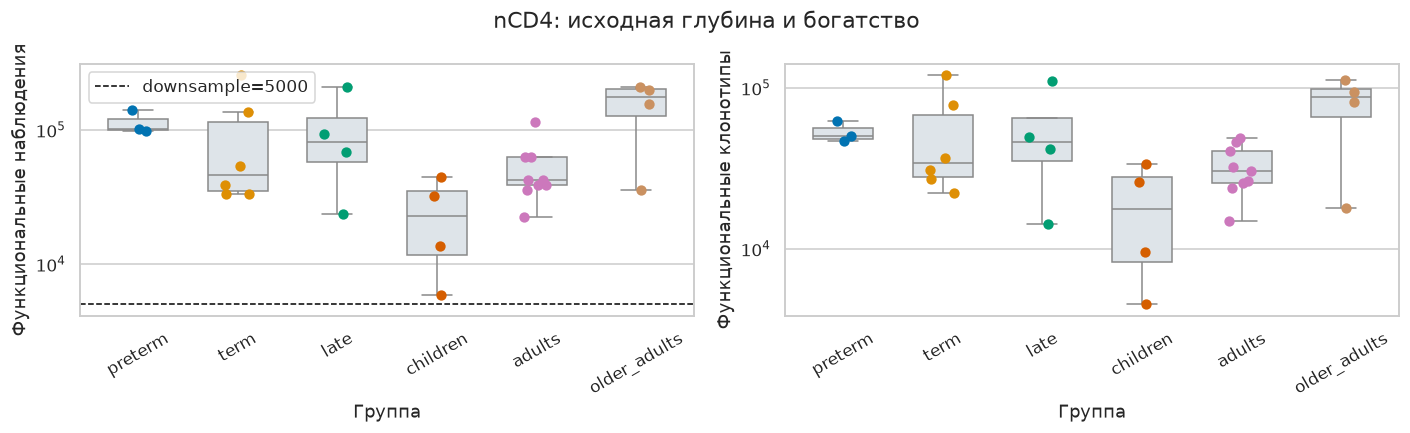

In [5]:
subset = 'nCD4'
r = results[subset]
display(pd.read_csv(OUTPUT / subset / 'group_summary.csv').round(4))
plot_qc(subset, r, metadata, FIGURES)

### Свойства CDR3

Каждая точка соответствует образцу. Длина измерена в аминокислотах, длина вставок в нуклеотидах. Заряд и гидропатия рассчитаны как в исходном ноутбуке, для центральных пяти аминокислот и полной CDR3.

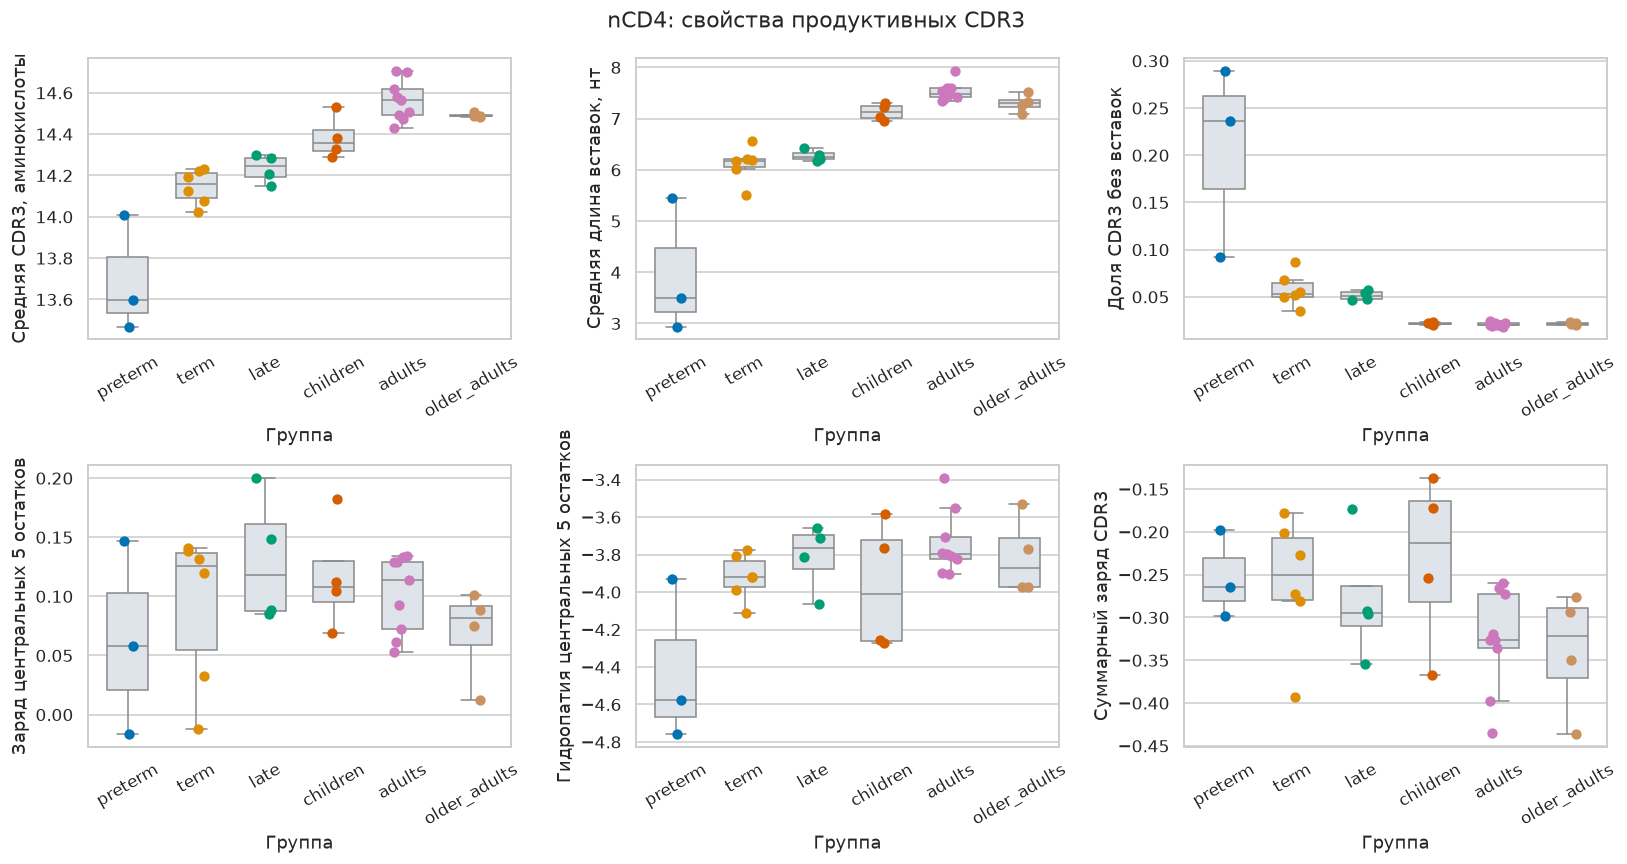

In [6]:
plot_properties(subset, r, metadata, FIGURES)

### Распределение длин CDR3

Линии показывают средние частотные профили групп. Светлая полоса показывает минимум и максимум между образцами, а не доверительный интервал. Справа отдельно показаны preterm и late.

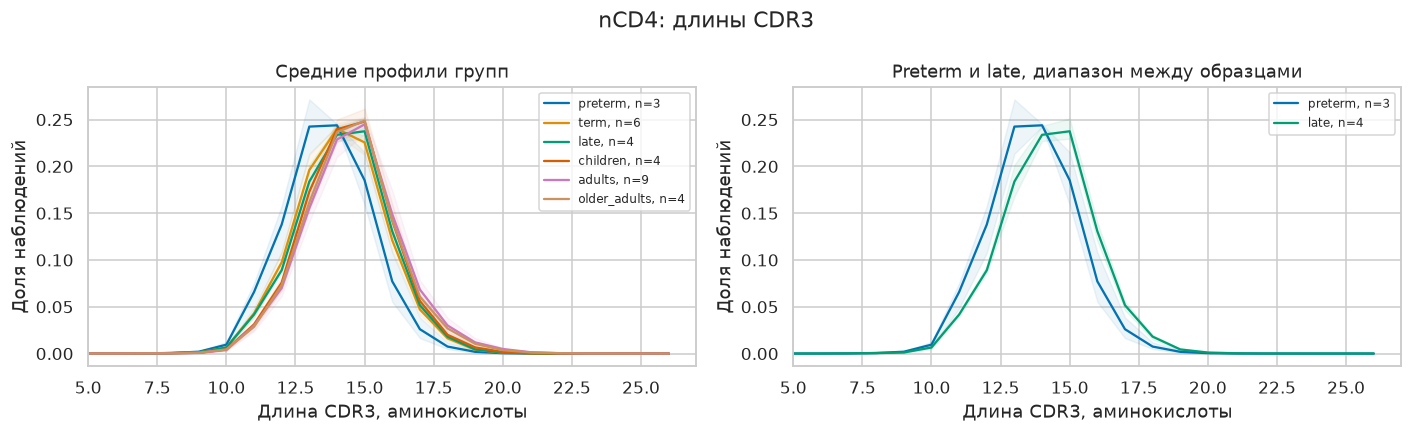

In [7]:
plot_lengths(subset, r, metadata, FIGURES)

### V/J usage

Цвет отражает среднюю по донорам долю наблюдений данного гена. Для V показаны 25 наиболее используемых генов. Для расчёта выбран лучший hit без аллеля, как в семинаре, неоднозначность аннотации не моделируется.

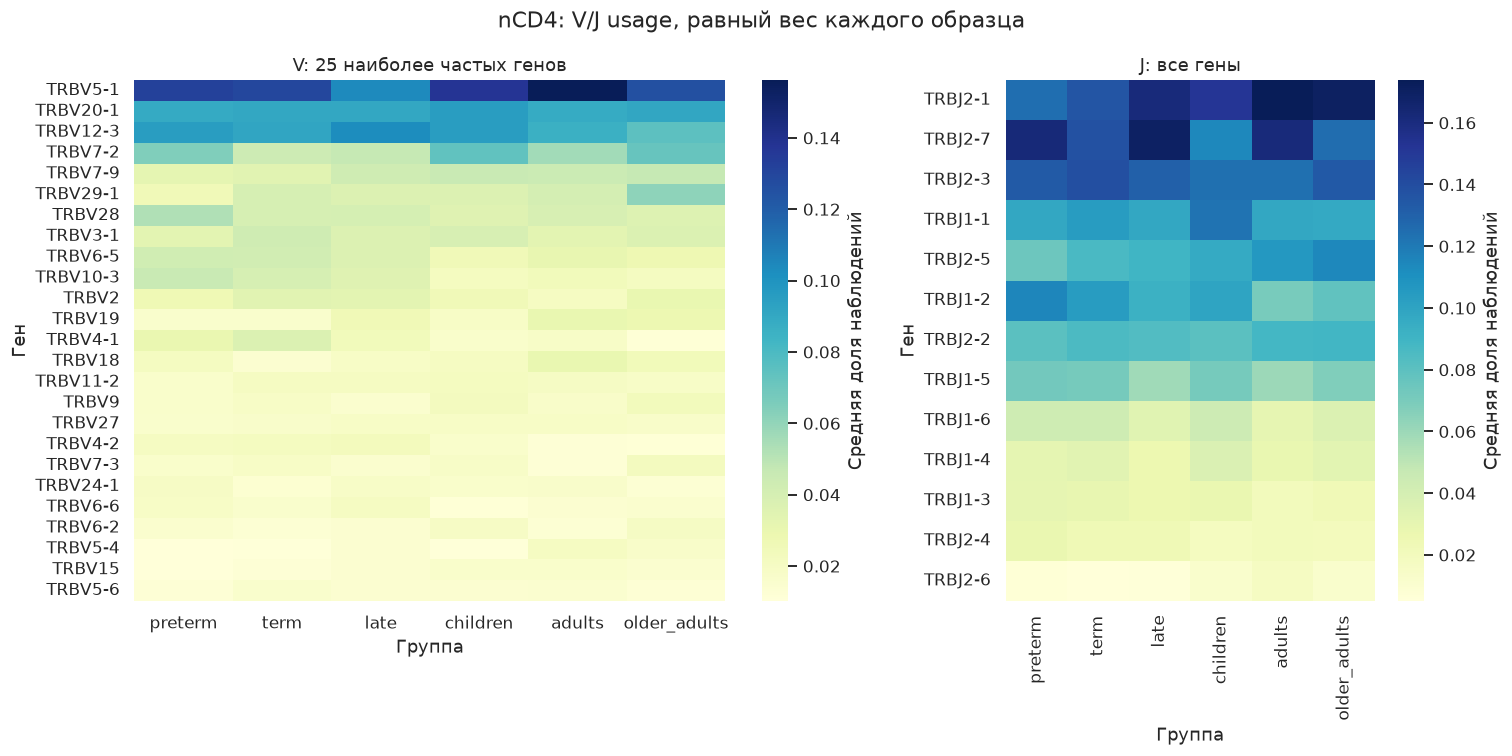

In [8]:
plot_usage(subset, r, metadata, FIGURES)

### Конвергенция

Отношение числа уникальных CDR3nt к CDR3aa, а также варианты с обязательным совпадением V и V+J. Значение выше 1 означает, что часть аминокислотных последовательностей кодируется разными нуклеотидными вариантами.

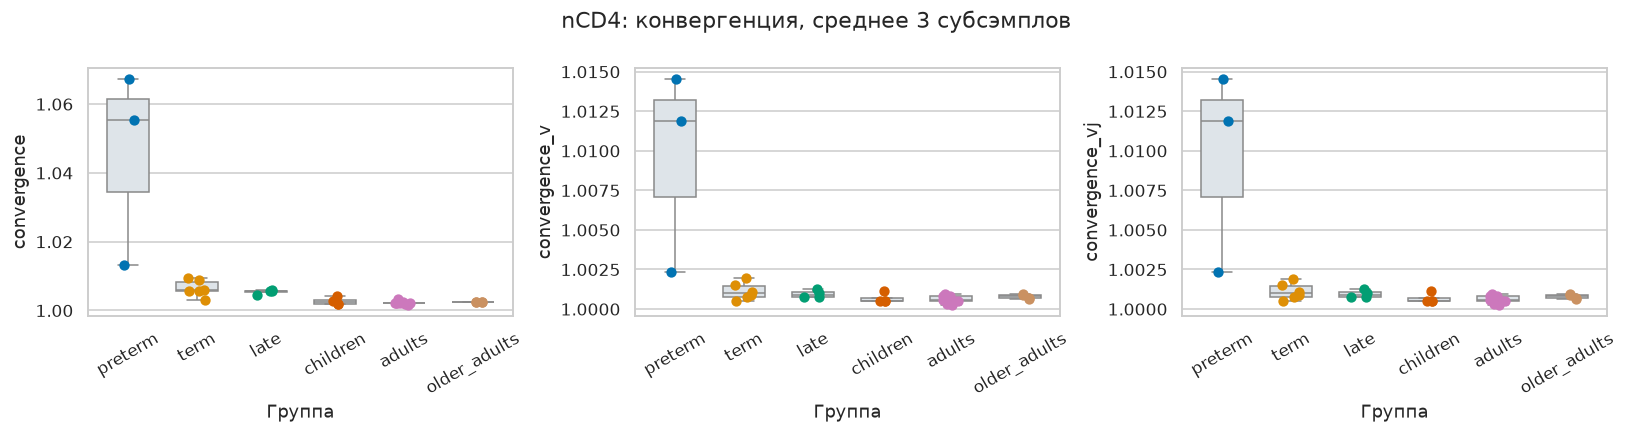

In [9]:
plot_convergence(subset, r, metadata, FIGURES)

### Альфа-разнообразие

Richness: обнаруженное число клонотипов. Shannon учитывает частоты. Clonality = 1 − H/ln(S). Simpson в `repseq` равен сумме квадратов частот, inverse Simpson его обратная величина. В каждом образце усреднены три субсэмпла.

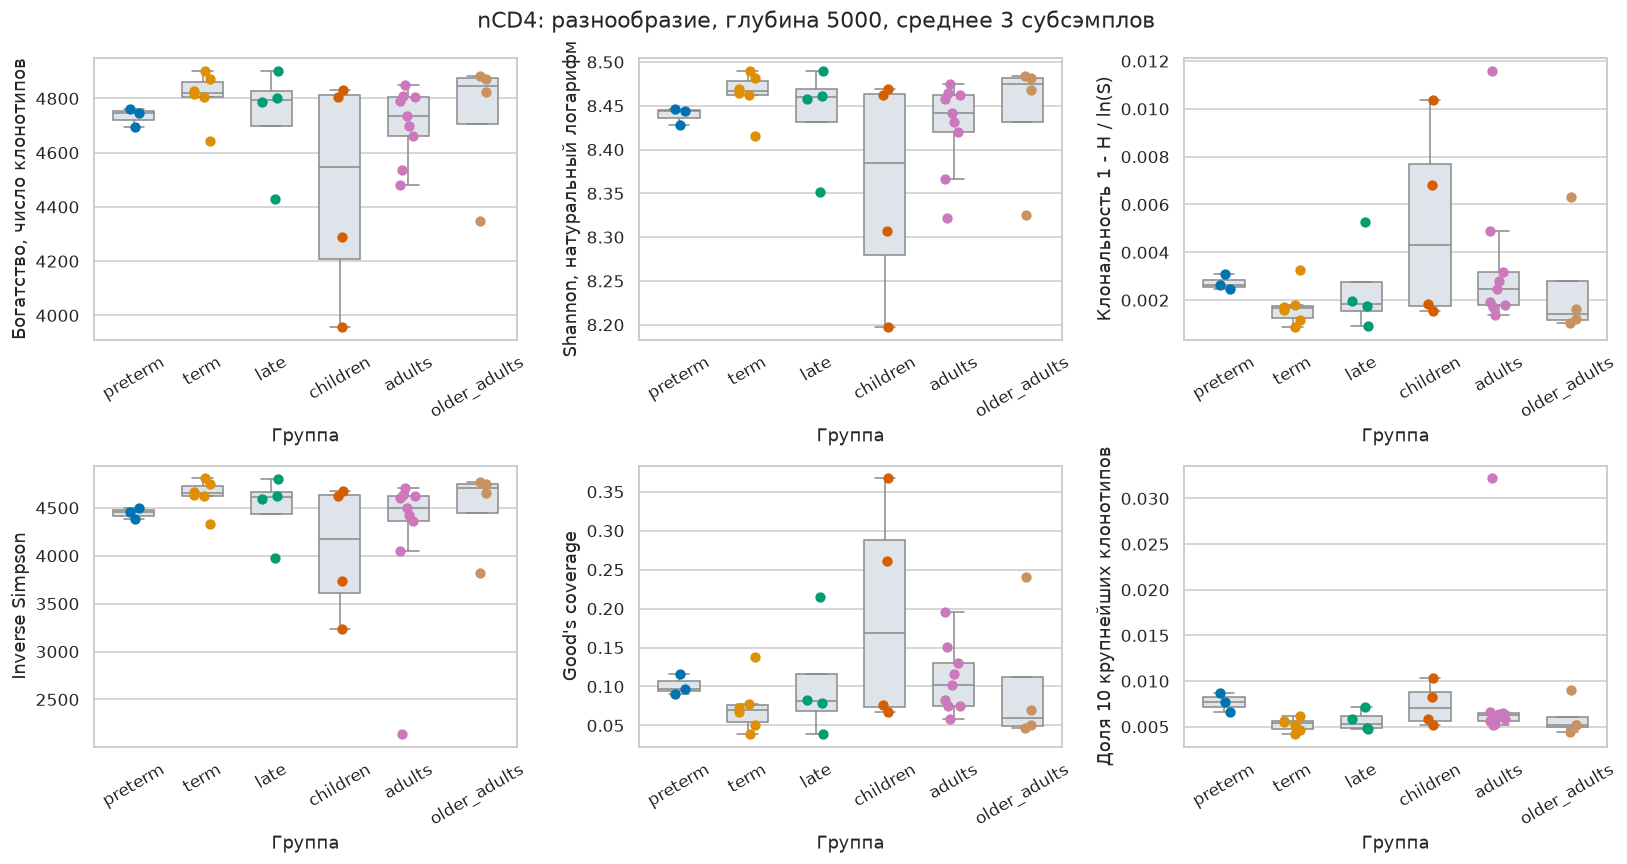

In [10]:
plot_alpha(subset, r, metadata, FIGURES)

### Rarefaction

Использовано точное ожидание без возвращения: E[S(m)] = Σᵢ [1 − C(N−nᵢ,m)/C(N,m)]. Это детерминированный аналог случайных кривых семинара. Конец каждой кривой равен наблюдаемому богатству полной функциональной библиотеки.

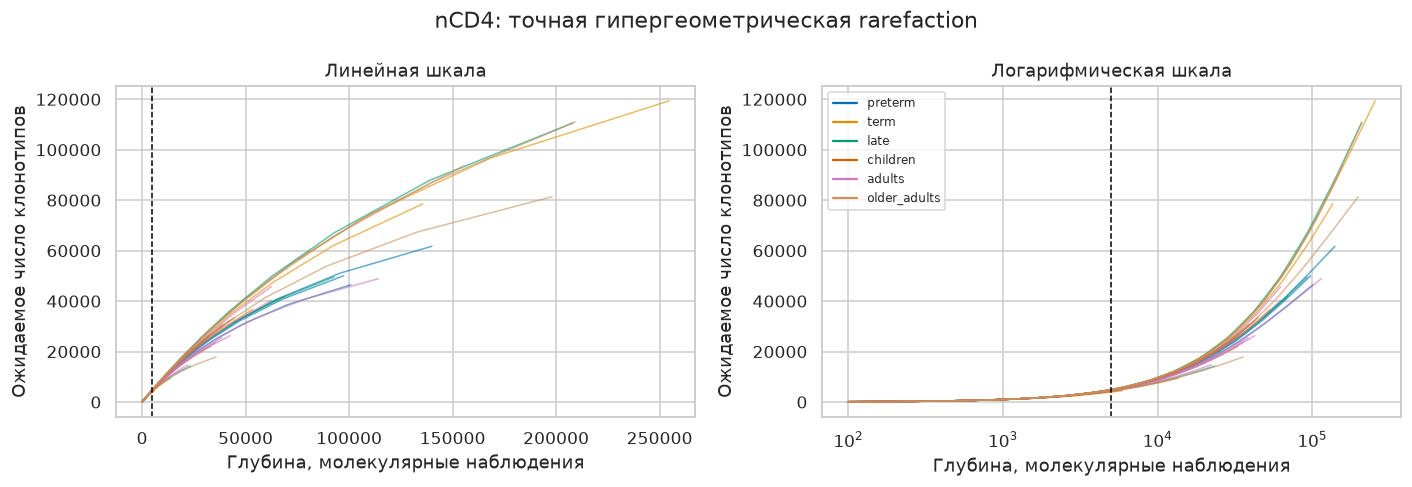

In [11]:
plot_rarefaction(subset, r, metadata, FIGURES)

### F2 и MDS

Совпадение клонотипов задаётся CDR3aa + V. F2 = Σᵢ√(pᵢqᵢ), где совпадающие ключи сначала объединяются. Для экономии памяти матрица рассчитана как произведение разреженных векторов √p. MDS построен функцией `repseq.beta.mds` по d = −log10(F2). MDS1/MDS2 условны. Карта сходства скрывает диагональ, её настоящее значение равно 1.

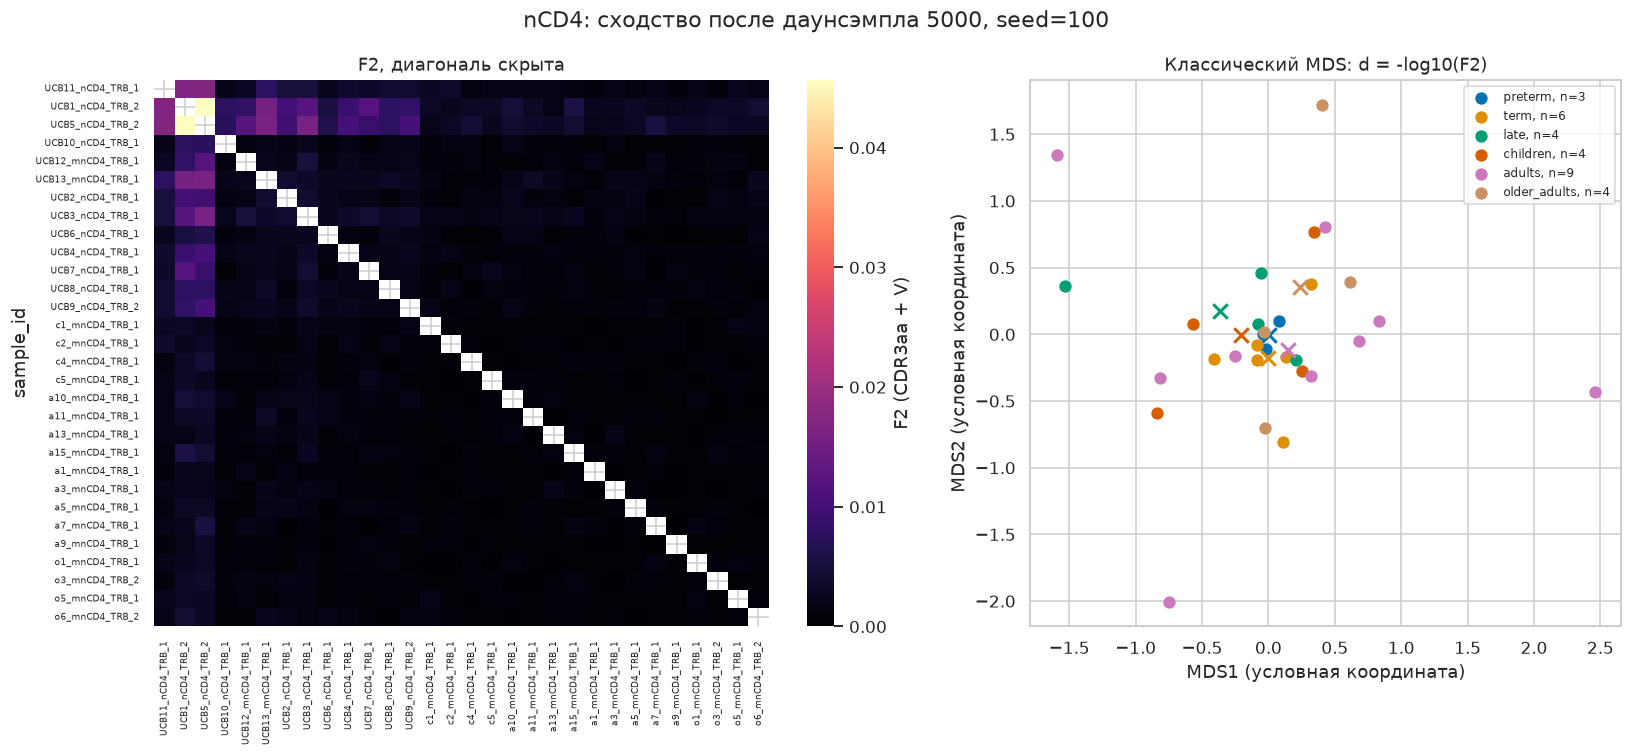

In [12]:
plot_beta(subset, r, metadata, FIGURES)

### Влияние глубины

Линия соединяет один и тот же образец при двух глубинах. Меньшая глубина уменьшает вероятность найти редкие клонотипы. Изменение абсолютного richness само по себе не означает биологического изменения.

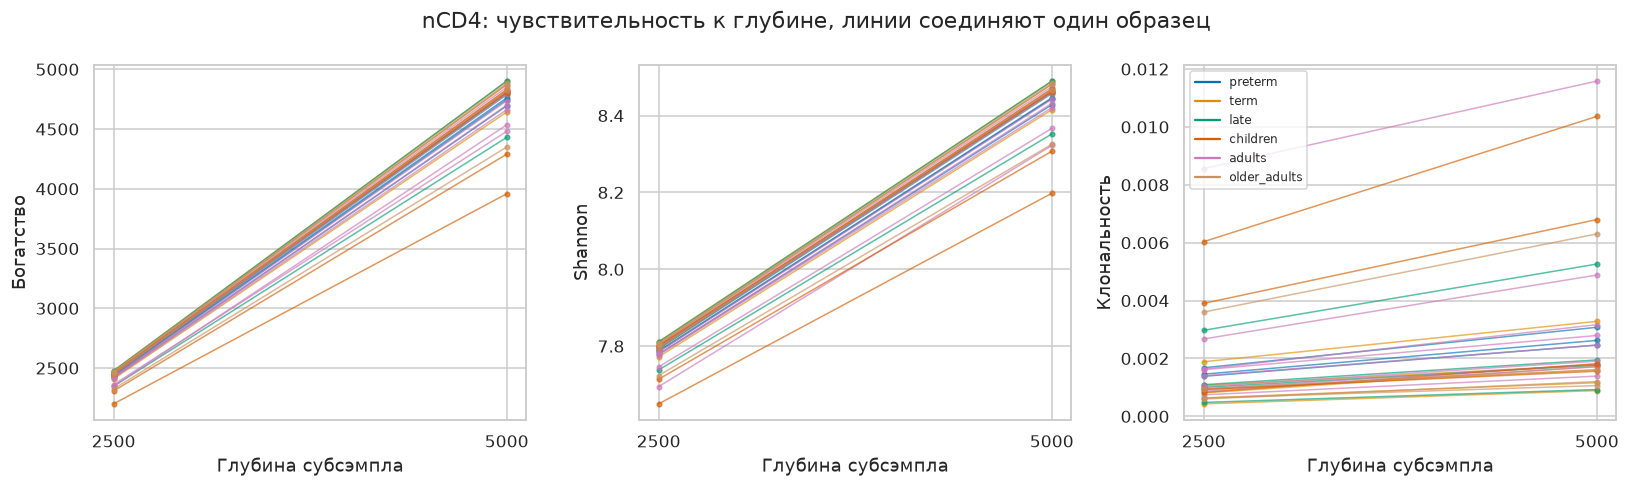

In [13]:
plot_sensitivity(subset, r, metadata, FIGURES)

### Интерпретация CD4

Здесь и далее сравниваются медианы показателей по донорам, а для стандартизированных метрик сначала усредняются три субсэмпла одного донора.

**CDR3 и вставки.** В preterm средняя длина CDR3 короче: медиана 13,60 аминокислоты против 14,24 в late и 14,56 у взрослых. Медиана длины вставок составляет 3,50 нт в preterm против 6,25 в late. Доля наблюдений без вставок выше: 23,62% против 5,09%. Сдвиг согласуется с различиями генерации V(D)J, но активность TdT здесь непосредственно не измерялась. Разброс заряда и гидропатии между образцами не даёт основания утверждать общую антигенную специфичность.

**V/J usage.** Во всех группах часто используется TRBV5-1: средняя по донорам доля составляет 10,39% в late и 15,61% у взрослых. TRBJ2-1 и TRBJ2-7 также входят в число наиболее используемых J-генов. Это различия состава репертуара, их нельзя автоматически приписывать одному антигену или возрасту.

**Конвергенция.** После даунсэмпла 5000 медиана CDR3nt/CDR3aa равна 1,0555 в preterm, 1,0055 в late и 1,0021 у взрослых. С требованием совпадения V+J конвергенция preterm снижается до 1,0119. Значит, часть конвергенции связана с одинаковой CDR3aa при разных сегментах. Различия в направлении согласуются с более короткими CDR3 preterm.

**Разнообразие.** При глубине 5000 медианы богатства лежат примерно от 4547 у детей до 4848 у старшей группы. Shannon составляет соответственно 8,384 и 8,474, клональность 0,00431 и 0,00141. Монотонного падения разнообразия с возрастом в CD4 нет. Столь близкое к размеру субсэмпла богатство означает, что большинство выбранных наблюдений относится к разным клонотипам. Много синглтонов и растущие rarefaction-кривые не позволяют считать биологический репертуар исчерпанным.

**F2 и MDS.** Медиана F2 для пар UCB-UCB равна 0,00317, для PB-PB 0,00060, для смешанных пар 0,00128. Медиана внутри preterm выше: 0,01712. Пересечение в целом мало и совместимо с более частыми общими короткими последовательностями в UCB. Пары образцов не являются независимыми репликами для статистического теста. Двумерный MDS сохраняет только 20,4% положительной инерции, поэтому чёткое разделение возрастных групп по одной карте утверждать нельзя.

**Чувствительность.** При уменьшении глубины 5000 до 2500 богатство по образцам в медиане падает на 48,90%, но ранговая корреляция Спирмена между двумя глубинами равна 0,980. Старшая группа сохраняет более высокое богатство, чем детская. Абсолютные richness и Shannon зависят от глубины, наблюдаемое отсутствие монотонного возрастного падения сохраняется.

## CD8

Для CD8 сохранены все 27 образцов, глубина основного субсэмпла 6000.

,experimental_group,n,reads_func,clones_func,mean_cdr3aa_len,mean_insert_size,zero_insert_freq,diversity,shannon_wiener,clonality,inverse_simpson,convergence,convergence_vj,top10_fraction
0,preterm,3,102609.0,45777.0,13.5859,3.2366,0.2681,5590.6667,8.5987,0.0035,5151.7417,1.0837,1.0143,0.0076
1,term,6,76396.0,46082.0,14.1563,5.8334,0.0742,5764.5000,8.6440,0.0018,5541.4189,1.0150,1.0026,0.0051
2,late,4,39571.0,24929.0,14.1850,6.1773,0.0584,5636.3333,8.6135,0.0027,5314.3265,1.0106,1.0018,0.0053
3,children,4,58813.5,40365.5,14.3617,7.0312,0.0244,5730.0000,8.6338,0.0022,5446.9412,1.0043,1.0007,0.0059
4,adults,4,20973.0,19618.0,14.4427,7.3657,0.0234,5859.1667,8.6634,0.0014,5617.9765,1.0037,1.0005,0.0052
5,older_adults,6,10720.5,6320.5,14.4451,7.1161,0.0253,5367.3333,8.4653,0.0143,1990.8198,1.0047,1.0013,0.0344


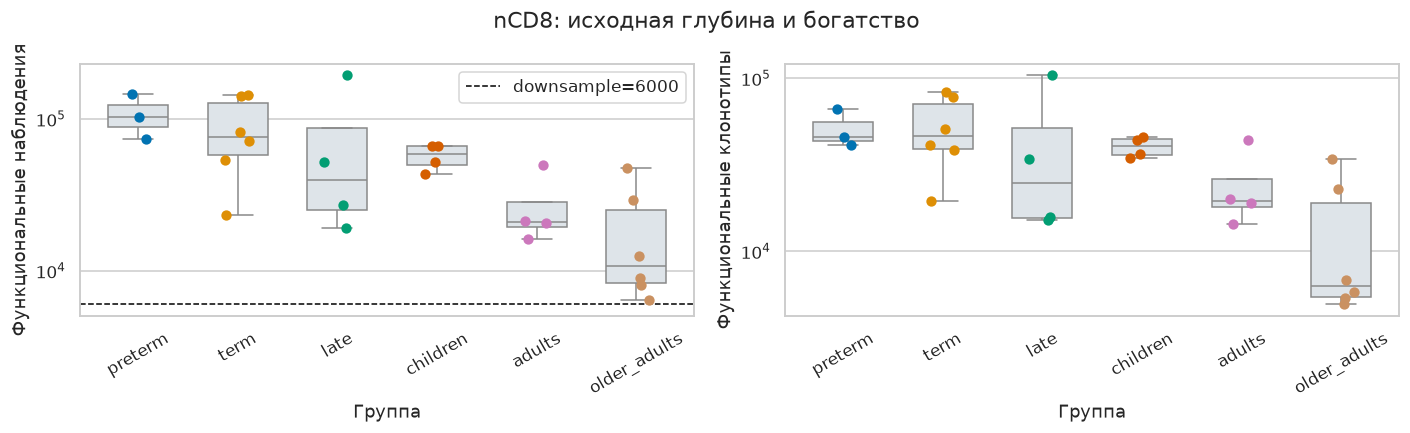

In [14]:
subset = 'nCD8'
r = results[subset]
display(pd.read_csv(OUTPUT / subset / 'group_summary.csv').round(4))
plot_qc(subset, r, metadata, FIGURES)

### Свойства CDR3

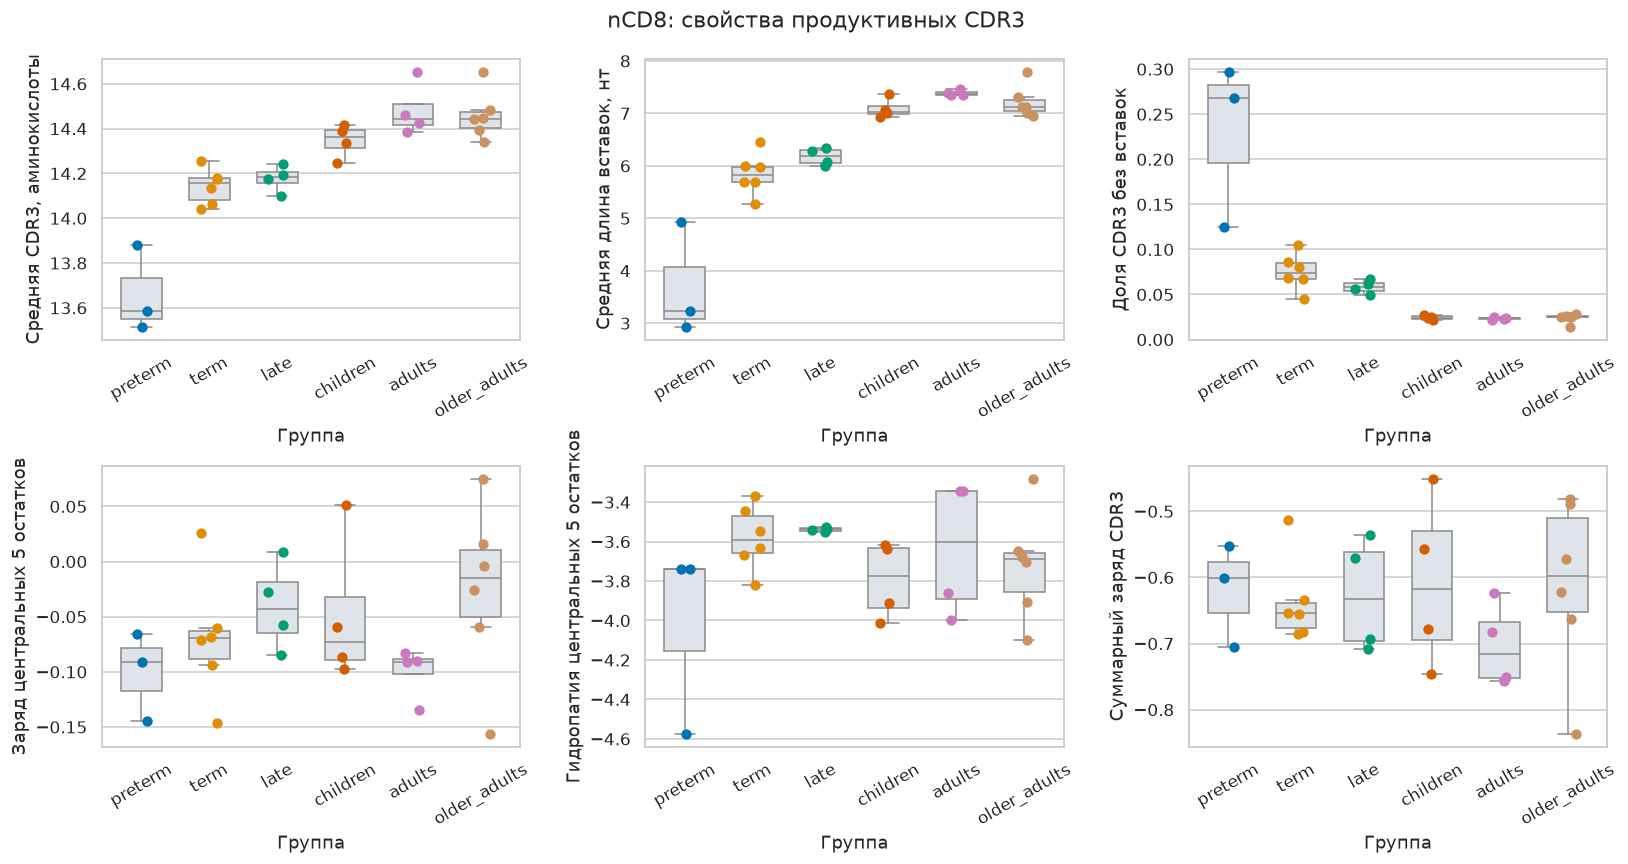

In [15]:
plot_properties(subset, r, metadata, FIGURES)

### Распределение длин CDR3

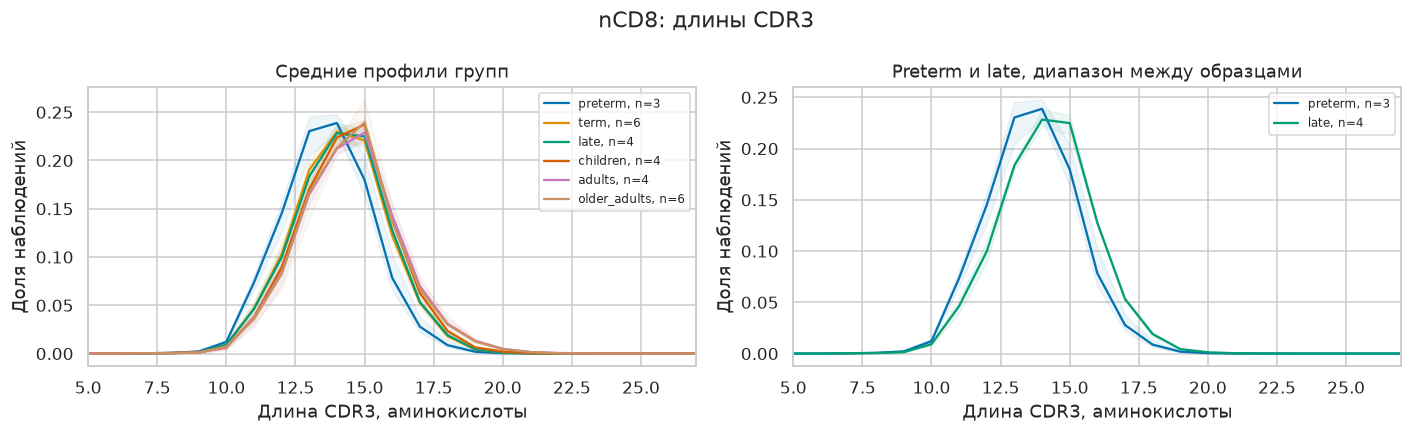

In [16]:
plot_lengths(subset, r, metadata, FIGURES)

### V/J usage

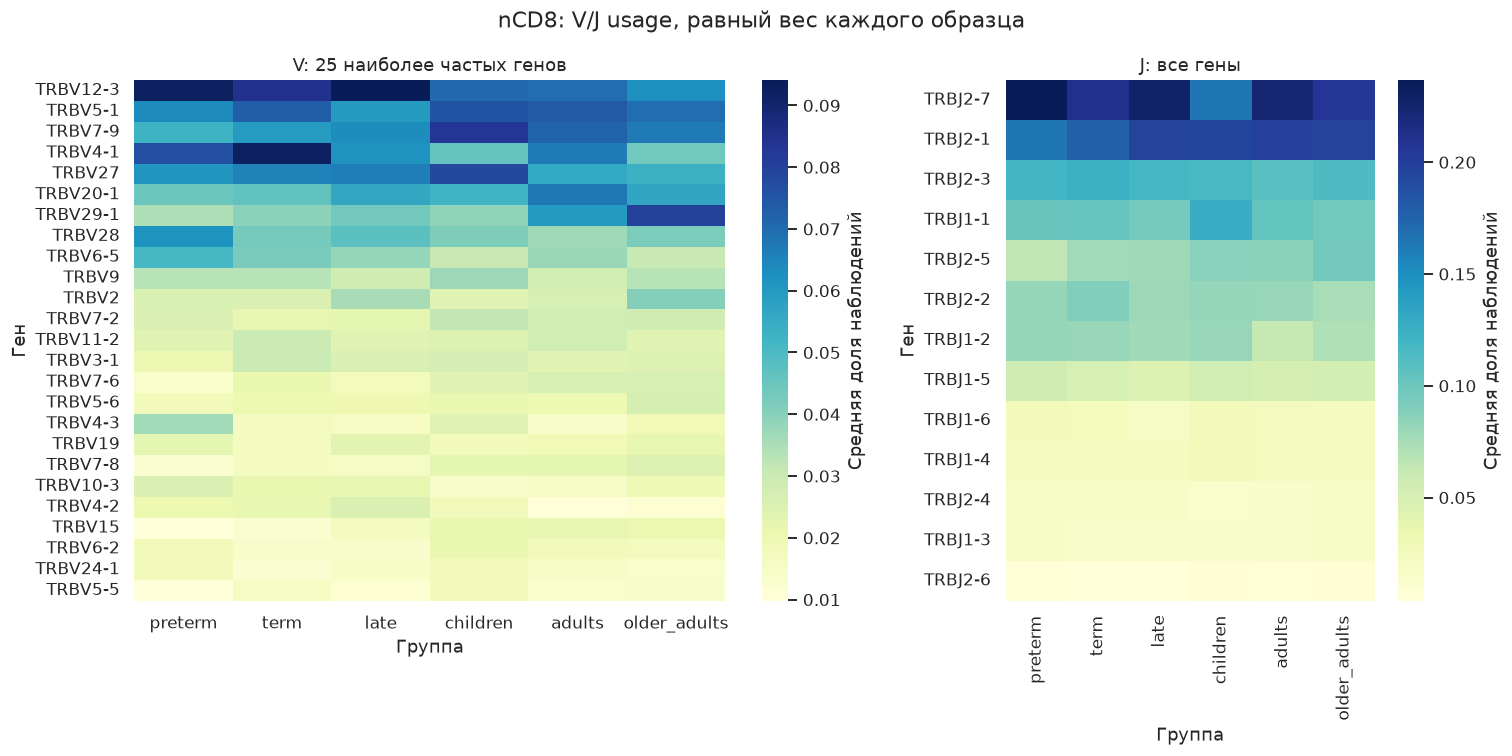

In [17]:
plot_usage(subset, r, metadata, FIGURES)

### Конвергенция

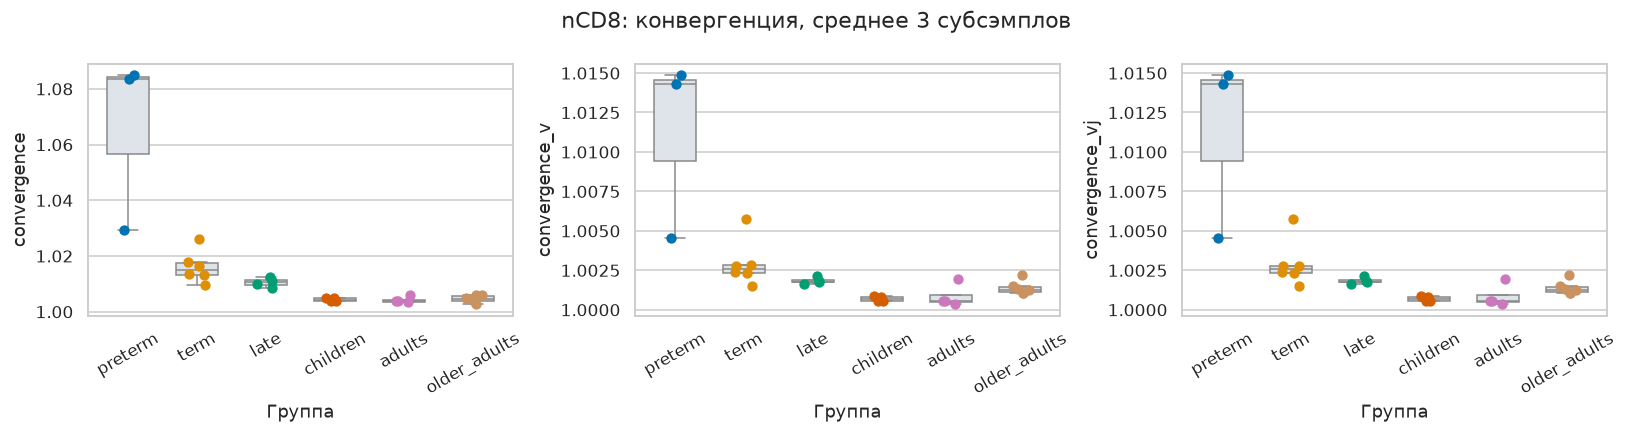

In [18]:
plot_convergence(subset, r, metadata, FIGURES)

### Альфа-разнообразие

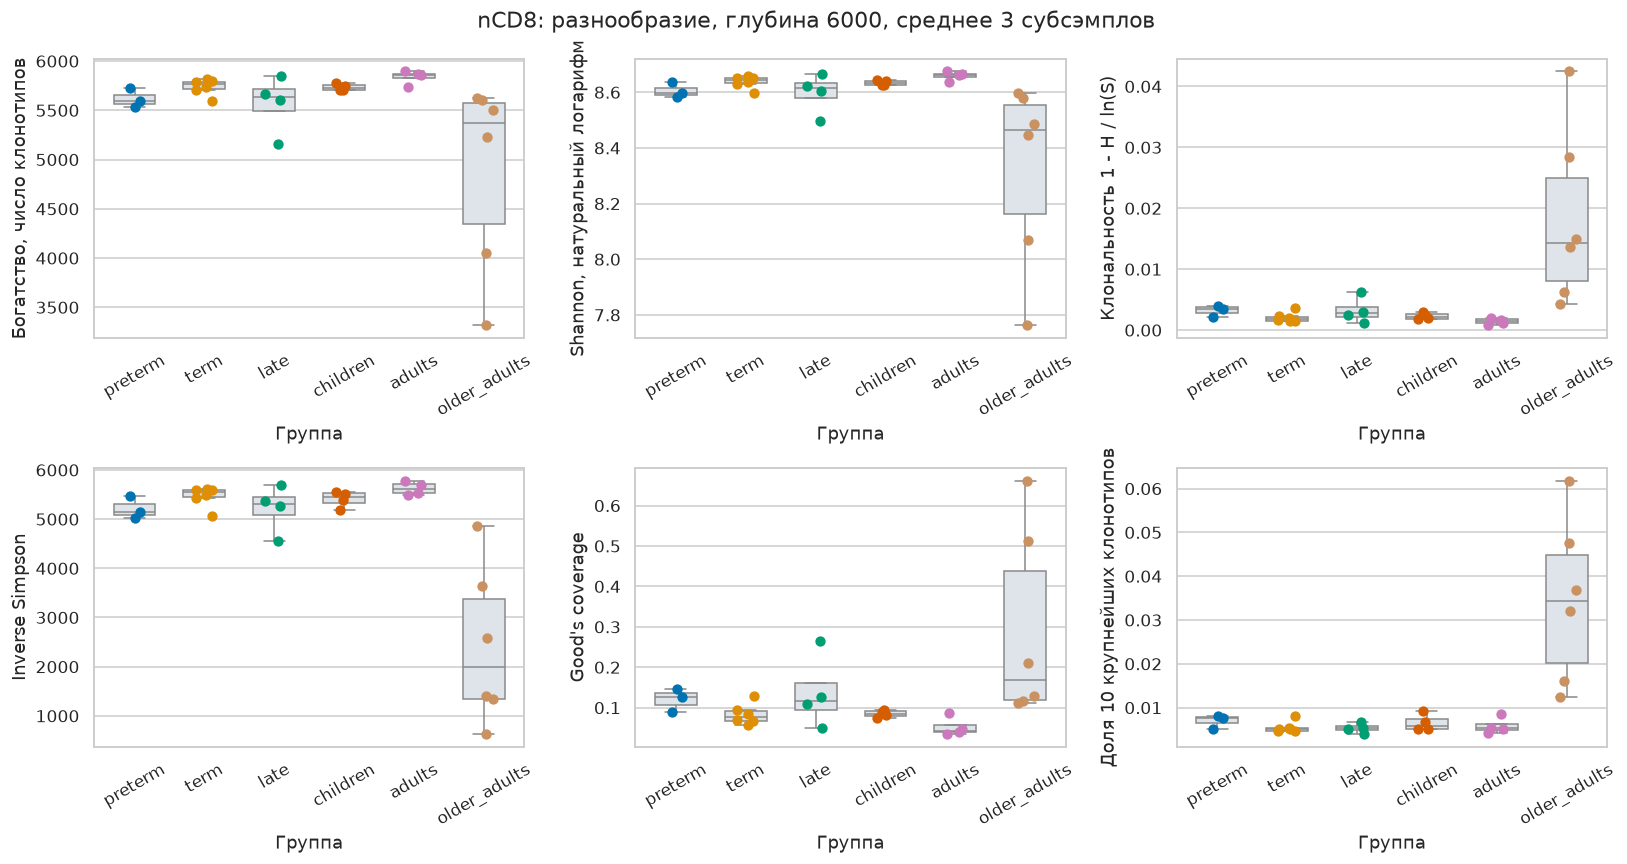

In [19]:
plot_alpha(subset, r, metadata, FIGURES)

### Rarefaction

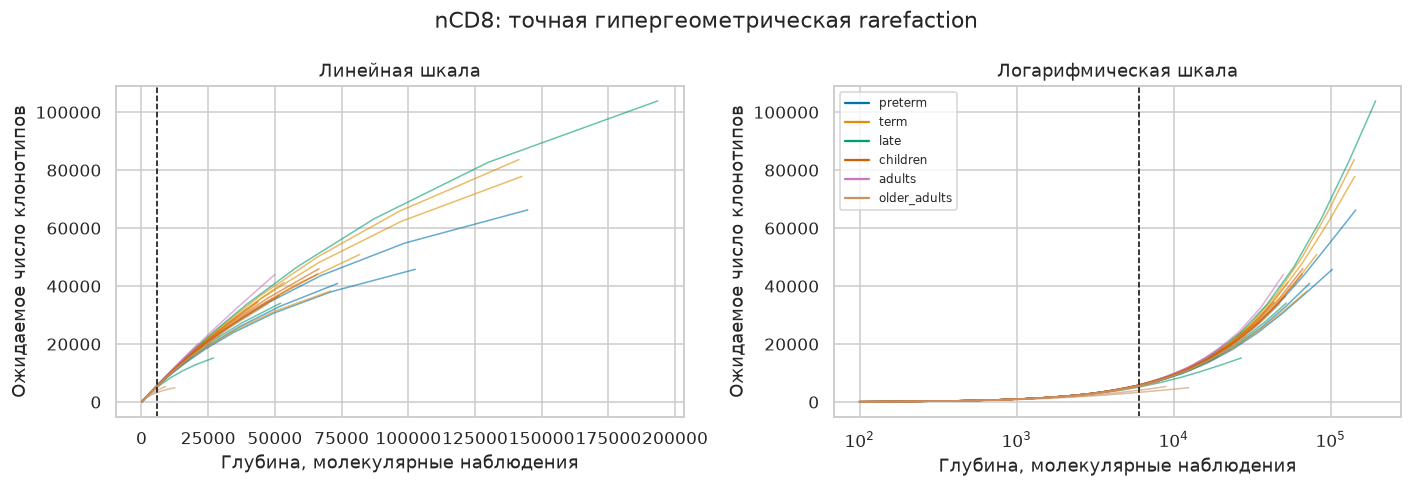

In [20]:
plot_rarefaction(subset, r, metadata, FIGURES)

### F2 и MDS

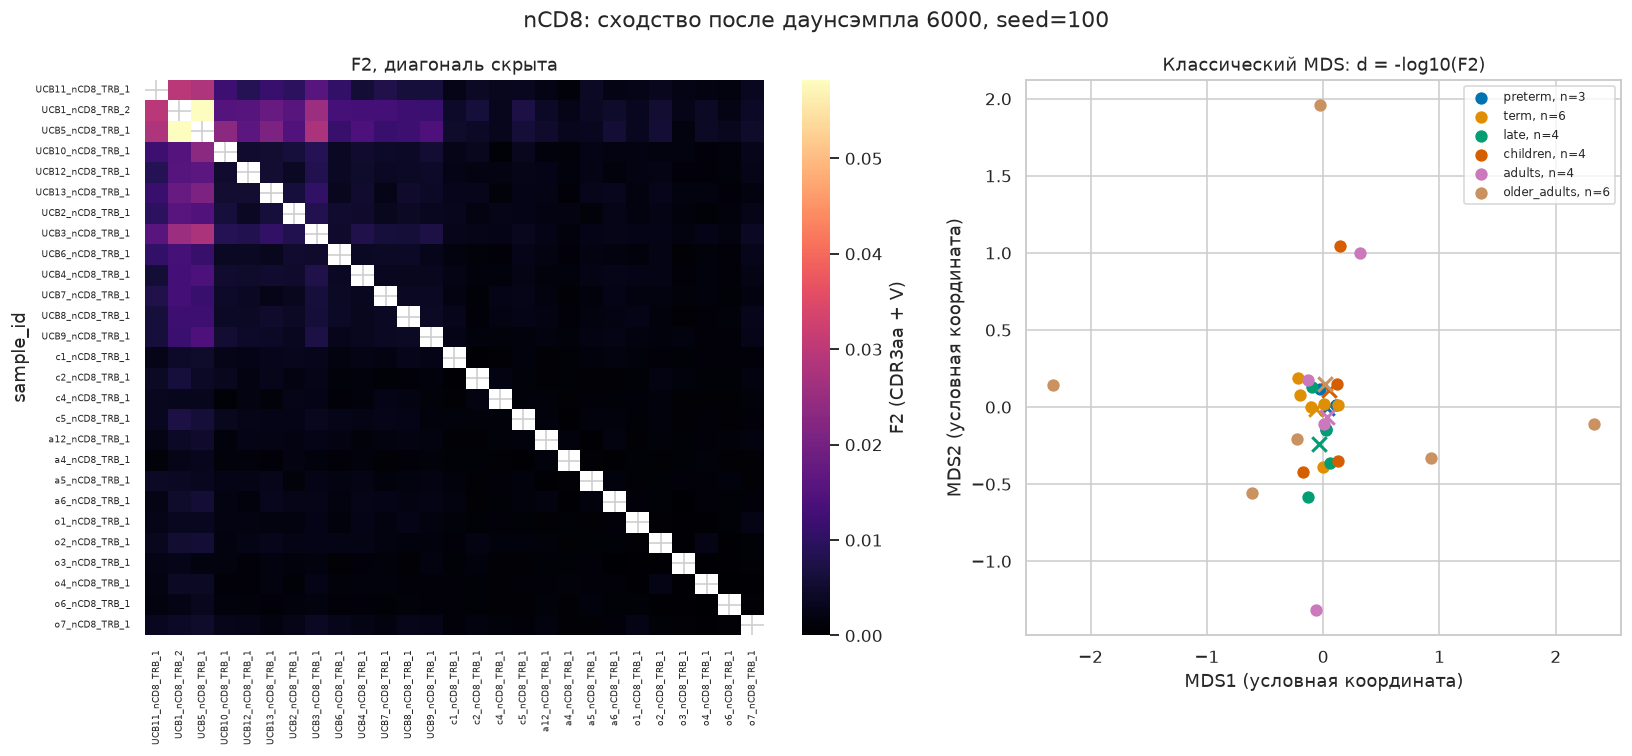

In [21]:
plot_beta(subset, r, metadata, FIGURES)

### Влияние глубины

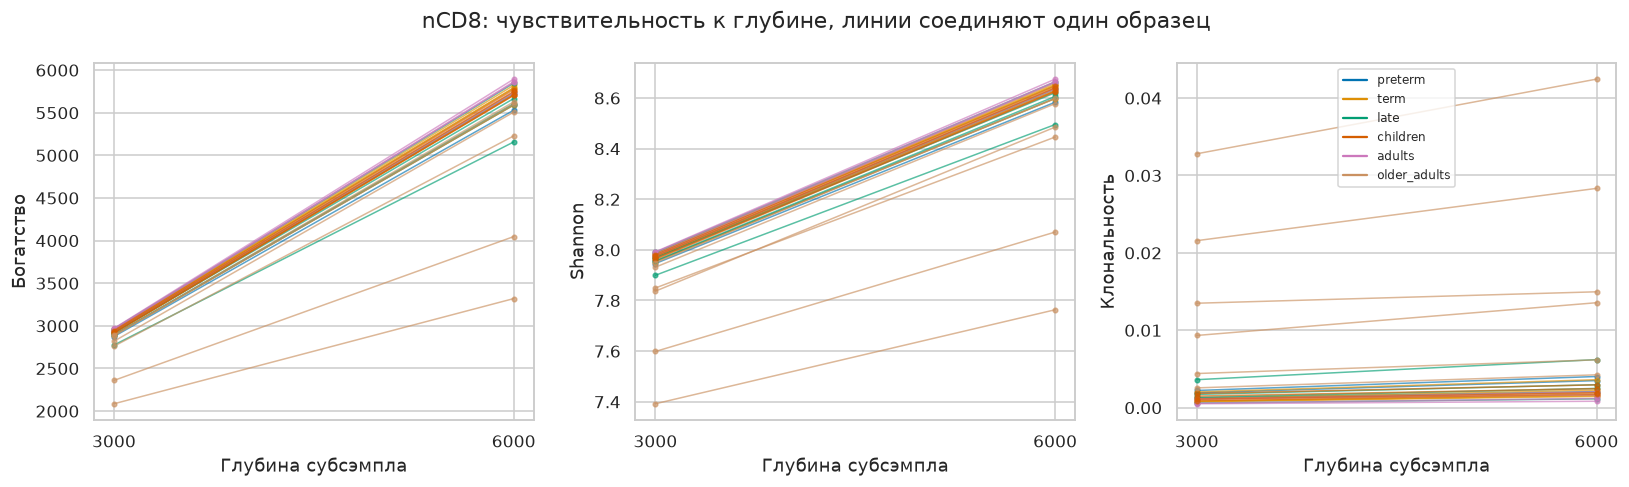

In [22]:
plot_sensitivity(subset, r, metadata, FIGURES)

### Интерпретация CD8

**CDR3 и вставки.** В preterm медиана средней длины CDR3 составляет 13,59 аминокислоты, в late 14,18, у взрослых 14,44. Медианная длина вставок равна 3,24, 6,18 и 7,37 нт соответственно. Доля наблюдений без вставок в preterm 26,81%, в late 5,84%, у взрослых 2,34%. Основное направление соответствует результатам CD4: у preterm короче CDR3 и меньше вставок. Это описание репертуара, причинная роль возраста этим сравнением не установлена.

**V/J usage.** Единственного доминирующего V-гена нет. Например, средняя доля TRBV12-3 составляет 9,26% в preterm и 9,41% в late; у старшей группы чаще используется TRBV29-1 (8,00%). В J-профиле велики доли TRBJ2-7 и TRBJ2-1. Средняя доля TRBJ2-7 равна 22,27% у взрослых. Изменение профиля генов само по себе не доказывает антигенный ответ.

**Конвергенция.** При глубине 6000 медиана конвергенции равна 1,0837 в preterm против 1,0106 в late и 1,0037 у взрослых. Для совпадения CDR3aa+V+J она ниже: 1,0143, 1,0018 и 1,0006. Наиболее выраженная конвергенция снова наблюдается в preterm, однако часть её исчезает при более строгом определении совпадения.

**Разнообразие и клональность.** У взрослых медиана богатства 5859 из 6000 наблюдений, у старшей группы 5367. Shannon равен 8,663 и 8,465, inverse Simpson 5618 и 1991. При этом клональность у старшей группы выше: 0,01426 против 0,00142, доля десяти крупнейших клонотипов 3,44% против 0,53%. Это согласованный описательный признак менее равномерного распределения частот в старшей группе. Между её донорами велик разброс, особенно выделяются несколько образцов. По этим данным нельзя отделить возраст от других факторов и установить причину концентрации частот. Исходная глубина старшей группы также заметно меньше.

**Rarefaction и сходство.** Кривые продолжают расти, насыщение репертуара не достигнуто. Медиана F2 равна 0,00622 для пар UCB-UCB, 0,00083 для PB-PB и 0,00209 для смешанных пар. Общих последовательностей в UCB больше, но по одному пересечению нельзя заключать общую антигенную специфичность. Первые две координаты MDS сохраняют только 22,4% положительной инерции и дают ограниченное представление всех расстояний.

**Чувствительность.** При переходе 6000 к 3000 богатство в медиане уменьшается на 48,82%, ранговая корреляция по донорам 0,982. У старшей группы клональность остаётся выше, чем у взрослых: 0,01141 против 0,00082. Значит, направление различия частот устойчиво к этой проверке глубины, хотя величина индексов меняется. Это проверка устойчивости, а не тест статистической значимости.

## Проверка результатов и ограничения

У каждого образца число функциональных клонотипов и сумма функциональных наблюдений сверены с метаданными. В каждом субсэмпле сохранено ровно заданное число наблюдений. Матрицы F2 симметричны, лежат в [0, 1] и имеют единичную диагональ. Дополнительно для пары UCB1/UCB2 в каждой популяции результат F2 сверен с `repseq.beta.metrics`: максимальное расхождение меньше 8×10⁻¹⁴. Выводы о сходстве относятся к CDR3aa + V, более строгое определение может уменьшить пересечение.

Биологические группы малы и не сбалансированы. Здесь нет продольных наблюдений одного человека и нет статистического теста значимости. Различие источника крови, сортировки клеток и глубины исходной библиотеки мешает приписать все различия одному возрасту. Одинаковая глубина уменьшает техническое смешение, но не устраняет его полностью.

Высокая конвергенция и сходство коротких CDR3 совместимы с особенностями генерации TCR и ограниченным набором перестроек. Они не доказывают общую антигенную специфичность. Клонотипы TRB не равны полной паре αβ-рецептора, число наблюдений не равно числу клеток. Кластеризация последовательностей в обязательную часть не включена.

## Источники

1. Исходный `ImmuneSem_students.zip`: `README.md`, `UCB_seminar.ipynb`, 87 клоносетов и `ucb_figshare_TRB_metadata.csv`.
2. Библиотека [repseq](https://pypi.org/project/repseq/0.1.3/), версия 0.1.3. Формулы конвергенции, индексов разнообразия и MDS проверены по установленному исходному коду.
3. [Документация MiXCR](https://mixcr.com/mixcr/reference/analysis-overview/) для разграничения upstream обработки и downstream анализа. BCR и TCR в итоговых таблицах не объединяются.